# 01 — Split Conformal Sanity Check

**Purpose.** Build a model-independent conformal pipeline on a small 10-class dataset before touching CheXpert. `sklearn.datasets.load_digits` is used only as a controlled proxy because it has ten classes and requires no external download.

This notebook checks three things:

1. the finite-sample corrected split-conformal quantile;
2. a simple probability/LAC score $s(x,y)=1-\hat p_y(x)$;
3. an Adaptive Prediction Sets (APS) score based on cumulative sorted probabilities.

The numerical results below are **not project results**. They are implementation sanity checks.

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

SEED = 42
ALPHA = 0.10
rng = np.random.default_rng(SEED)


## 1. Train a deliberately simple black-box classifier

In [2]:

X, y = load_digits(return_X_y=True)

X_train, X_hold, y_train, y_hold = train_test_split(
    X, y, test_size=0.50, random_state=SEED, stratify=y
)
X_cal, X_test, y_cal, y_test = train_test_split(
    X_hold, y_hold, test_size=0.50, random_state=SEED, stratify=y_hold
)

model = LogisticRegression(max_iter=3000)
model.fit(X_train, y_train)

cal_probs = model.predict_proba(X_cal)
test_probs = model.predict_proba(X_test)

print('train/cal/test:', len(y_train), len(y_cal), len(y_test))
print('test accuracy:', round(accuracy_score(y_test, model.predict(X_test)), 4))


train/cal/test: 898 449 450
test accuracy: 0.9644


## 2. Finite-sample conformal quantile

For $n$ calibration scores and miscoverage level $\alpha$, use the conservative empirical quantile at

$$
\frac{\lceil (n+1)(1-\alpha)\rceil}{n}.
$$

In [3]:

def conformal_quantile(scores, alpha=0.1):
    scores = np.asarray(scores, dtype=float)
    n = len(scores)
    level = min(np.ceil((n + 1) * (1 - alpha)) / n, 1.0)
    return np.quantile(scores, level, method='higher')


## 3. Simple probability/LAC score

Use

$$s(x,y)=1-\hat p_y(x).$$

A candidate label is included when its score is no greater than the calibrated threshold.

In [4]:

cal_scores_lac = 1.0 - cal_probs[np.arange(len(y_cal)), y_cal]
q_lac = conformal_quantile(cal_scores_lac, ALPHA)

lac_sets = (1.0 - test_probs) <= q_lac

print('LAC qhat:', round(float(q_lac), 4))


LAC qhat: 0.1461


## 4. Evaluation functions

In [5]:

def evaluate_sets(pred_sets, labels, n_classes=10):
    covered = pred_sets[np.arange(len(labels)), labels]
    sizes = pred_sets.sum(axis=1)
    rows = []
    for c in range(n_classes):
        mask = labels == c
        rows.append({
            'class': c,
            'n': int(mask.sum()),
            'coverage': float(covered[mask].mean()),
            'mean_set_size': float(sizes[mask].mean()),
        })
    return {
        'marginal_coverage': float(covered.mean()),
        'mean_set_size': float(sizes.mean()),
        'singleton_fraction': float((sizes == 1).mean()),
        'empty_fraction': float((sizes == 0).mean()),
        'class_table': pd.DataFrame(rows),
    }

lac_eval = evaluate_sets(lac_sets, y_test)
print({k: round(v, 4) for k, v in lac_eval.items() if k != 'class_table'})
lac_eval['class_table']


{'marginal_coverage': 0.9178, 'mean_set_size': 0.9311, 'singleton_fraction': 0.9311, 'empty_fraction': 0.0689}


,class,n,coverage,mean_set_size
0,0,44,0.977273,0.977273
1,1,46,0.913043,0.934783
2,2,44,0.931818,0.931818
3,3,46,0.978261,0.978261
4,4,46,0.956522,0.956522
5,5,46,0.934783,0.956522
6,6,46,0.913043,0.934783
7,7,44,0.954545,0.954545
8,8,43,0.813953,0.837209
9,9,45,0.800000,0.844444


## 5. Randomized Adaptive Prediction Sets (APS)

Romano, Sesia and Candès define a generalized inverse-quantile score using an independent $U\sim\mathrm{Uniform}(0,1)$. For a candidate label of rank $r$, the randomized score can be written as the cumulative probability of all more-likely labels plus a random fraction of the candidate label's probability. This avoids the overly coarse behaviour of the simple deterministic cumulative score when the classifier is very confident.

The prediction set is then generated using the corresponding randomized boundary rule. Empty sets are possible in the randomized construction and are therefore left intact rather than forcibly adding the top class.

In [6]:

def randomized_aps_calibration_scores(probs, labels, rng):
    order = np.argsort(-probs, axis=1)
    sorted_probs = np.take_along_axis(probs, order, axis=1)
    cumulative = np.cumsum(sorted_probs, axis=1)
    inverse_order = np.argsort(order, axis=1)
    ranks = inverse_order[np.arange(len(labels)), labels]

    previous_mass = np.zeros(len(labels))
    has_previous = ranks > 0
    previous_mass[has_previous] = cumulative[
        np.arange(len(labels))[has_previous], ranks[has_previous] - 1
    ]

    p_true = probs[np.arange(len(labels)), labels]
    u = rng.random(len(labels))
    return previous_mass + (1.0 - u) * p_true


def randomized_aps_prediction_sets(probs, qhat, rng):
    n, k = probs.shape
    order = np.argsort(-probs, axis=1)
    sorted_probs = np.take_along_axis(probs, order, axis=1)
    cumulative = np.cumsum(sorted_probs, axis=1)
    u = rng.random(n)

    pred_sets = np.zeros((n, k), dtype=bool)

    for i in range(n):
        boundary = np.searchsorted(cumulative[i], qhat, side='left')
        boundary = min(boundary, k - 1)

        boundary_prob = sorted_probs[i, boundary]
        overshoot_fraction = (
            (cumulative[i, boundary] - qhat) / boundary_prob
            if boundary_prob > 0 else 0.0
        )

        # Include all labels before the boundary. Include the boundary
        # label unless the randomization removes it.
        n_include = boundary if u[i] <= overshoot_fraction else boundary + 1
        if n_include > 0:
            pred_sets[i, order[i, :n_include]] = True

    return pred_sets

aps_cal_rng = np.random.default_rng(SEED + 1)
aps_test_rng = np.random.default_rng(SEED + 2)

cal_scores_aps = randomized_aps_calibration_scores(cal_probs, y_cal, aps_cal_rng)
q_aps = conformal_quantile(cal_scores_aps, ALPHA)
aps_sets = randomized_aps_prediction_sets(test_probs, q_aps, aps_test_rng)

aps_eval = evaluate_sets(aps_sets, y_test)
print('APS qhat:', round(float(q_aps), 4))
print({k: round(v, 4) for k, v in aps_eval.items() if k != 'class_table'})
aps_eval['class_table']


APS qhat: 0.9269
{'marginal_coverage': 0.92, 'mean_set_size': 1.02, 'singleton_fraction': 0.8756, 'empty_fraction': 0.0622}


,class,n,coverage,mean_set_size
0,0,44,0.886364,0.886364
1,1,46,0.978261,1.130435
2,2,44,0.977273,1.022727
3,3,46,0.891304,0.934783
4,4,46,0.956522,1.043478
5,5,46,0.891304,0.978261
6,6,46,0.869565,0.956522
7,7,44,0.931818,1.000000
8,8,43,0.953488,1.093023
9,9,45,0.866667,1.155556


## 6. Compare methods

In [7]:

comparison = pd.DataFrame([
    {
        'method': 'LAC / probability score',
        'marginal_coverage': lac_eval['marginal_coverage'],
        'mean_set_size': lac_eval['mean_set_size'],
        'singleton_fraction': lac_eval['singleton_fraction'],
    },
    {
        'method': 'APS',
        'marginal_coverage': aps_eval['marginal_coverage'],
        'mean_set_size': aps_eval['mean_set_size'],
        'singleton_fraction': aps_eval['singleton_fraction'],
    },
])
comparison


,method,marginal_coverage,mean_set_size,singleton_fraction
0,LAC / probability score,0.917778,0.931111,0.931111
1,APS,0.920000,1.020000,0.875556


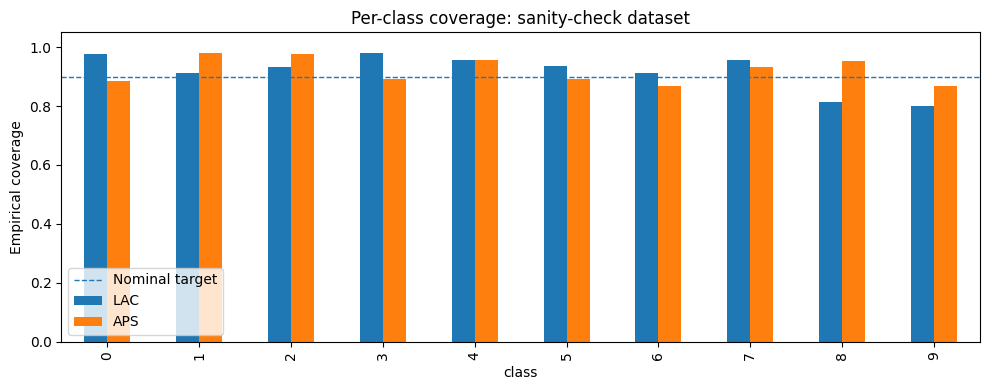

In [8]:

plot_df = lac_eval['class_table'][['class', 'coverage']].rename(columns={'coverage':'LAC'})
plot_df['APS'] = aps_eval['class_table']['coverage']

ax = plot_df.set_index('class').plot(kind='bar', figsize=(10, 4))
ax.axhline(1 - ALPHA, linestyle='--', linewidth=1, label='Nominal target')
ax.set_ylim(0, 1.05)
ax.set_ylabel('Empirical coverage')
ax.set_title('Per-class coverage: sanity-check dataset')
ax.legend()
plt.tight_layout()
plt.show()


## 7. What this tells us — and what it does not

- If marginal coverage is near the nominal 90% target, that is a useful software sanity check.
- Per-class coverage can still vary because the formal guarantee here is marginal, not class-conditional.
- Randomized APS can produce empty sets for some examples; that is part of the randomized construction rather than a bug.
- Any differences observed on digits are **not evidence about CheXpert**.
- The next genuine experiment should only begin after the supervisor agrees the exact single-label CheXpert construction.

### Next implementation steps

1. Add class-conditional calibration with one threshold per class.
2. Repeat calibration over many seeds and calibration sizes.
3. Replace digits probabilities with stored CheXpert classifier probabilities once the data formulation is fixed.